# Horizontal TDOA Voting vs Beamforming

In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code")  # folder containing HATS_functions.py

from HATS_functions import gcc_phat, corr_to_itd

angles = ["0", "45", "90", "315"]
PathToFiles = "../Audio_Files/Real_World_Measurements/Horizontal"

num_mics = 7
angle_increment = 360/num_mics
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-Audio.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")

In [2]:
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def plot_array_voting(scores, true_source_deg, save_path=None):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    max_score = max(scores.values())

    # Outer mics
    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        size = 200 + 800 * intensity
        color = cm.Blues(0.3 + 0.7 * intensity)

        ax.scatter(a, mic_r, s=size, color=color, zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 1.15), ha='center', fontsize=9)

    # Centre mic
    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    size_c = 200 + 800 * intensity_c
    color_c = cm.Blues(0.3 + 0.7 * intensity_c)

    ax.scatter(0, 0, s=size_c, color=color_c, zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)

    # Winning sector 
    outer_scores = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer_scores.items(), key=lambda x: -x[1])
    winning_mic = int(sorted_mics[0][0])
    second_mic = int(sorted_mics[1][0])

    a1 = mic_angles_deg[winning_mic - 1]
    a2 = mic_angles_deg[second_mic - 1]

    delta = ((a2 - a1 + 180) % 360) - 180

    if delta >= 0:
        sector_start = np.radians(a1)
        sector_end = np.radians(a1 + delta)
    else:
        sector_start = np.radians(a1 + delta)
        sector_end = np.radians(a1)

    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='steelblue',
                label='Estimated sector')

    # Array ring 
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # True source
    source_angle_rad = np.radians(true_source_deg)
    source_r = 0.08
    ax.plot([source_angle_rad, source_angle_rad], [0, source_r],
            color='coral', lw=2)
    ax.plot(source_angle_rad, source_r, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'DOA — Array TDOA Voting Estimate ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()

    if save_path:
        fig.savefig(f"{save_path}.png", dpi=200, bbox_inches='tight')
        fig.savefig(f"{save_path}.pdf", bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [3]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

vote_results = {}

def compute_votes(source_angle_key):
    scores = {str(i): 0 for i in range(7)}
    for i in range(7):
        datax, fs = sf.read(recordings[source_angle_key][str(i)])
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings[source_angle_key][str(j)])
            correlation = gcc_phat(datax, datay)
            itd = corr_to_itd(correlation, dists[i][j], fs)
            if itd < 0:
                scores[str(i)] += 1
            else:
                scores[str(j)] += 1
    return scores


for source_angle in recordings.keys():
    scores = compute_votes(source_angle)
    vote_results[source_angle] = scores
    #plot_array_voting(scores, float(source_angle), figures_dir / f"array_voting_{source_angle}")

In [4]:
from pathlib import Path
import pyroomacoustics as pra
import numpy as np
import soundfile as sf

# Mic positions 
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([r*np.cos(theta), r*np.sin(theta)])

mic_positions = np.array(positions).T 

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')
    
def plot_music_doa(doa, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    for a in mic_angles_rad:
        ax.scatter(a, mic_r, s=200, color=cm.Blues(0.6), zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
    ax.scatter(0, 0, s=200, color=cm.Blues(0.6), zorder=5,
               edgecolors='steelblue', linewidths=1.5)

    for a, label in zip(mic_angles_rad, range(1, 7)):
        ax.annotate(f'Mic {label}', (a, mic_r * 1.15), ha='center', fontsize=9)

    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # MUSIC spectrum
    azimuth = doa.grid.azimuth
    spectrum = doa.grid.values
    spectrum_norm = spectrum / spectrum.max()

    spectrum_r_min = 0.005
    spectrum_r_max = mic_r * 0.9
    spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

    ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4,
                    color='steelblue', label='MUSIC spectrum')
    ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

    # Estimated DOA
    estimated_rad = doa.azimuth_recon[0]
    estimated_deg = np.degrees(estimated_rad)
    ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue',
            linestyle='--', linewidth=2)
    ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10,
            label=f'Estimated ({estimated_deg:.1f}°)')

    # True source
    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'SRP-PHAT — Array DOA ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)
    
def run_music(source_angle_key):
    signals = []
    for i in range(7):
        data, fs = sf.read(recordings[source_angle_key][str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    doa = pra.doa.algorithms['MUSIC'](mic_positions, fs, nfft, c=343, num_src=1)
    doa.locate_sources(X)
    return doa

# Save
music_results = {}
for angle_key in recordings.keys():
    print(f"MUSIC for {angle_key}°...")
    doa = run_music(angle_key)
    music_results[angle_key] = [np.degrees(doa.azimuth_recon[0]), doa]
    #plot_music_doa(doa, float(angle_key), f"music_{angle_key}")

MUSIC for 0°...
MUSIC for 45°...
MUSIC for 90°...
MUSIC for 315°...


# Comparison Plots

In [5]:
music_results

{'0': [np.float64(359.0), <pyroomacoustics.doa.music.MUSIC at 0x11c1d4ec0>],
 '45': [np.float64(42.0), <pyroomacoustics.doa.music.MUSIC at 0x11c07f390>],
 '90': [np.float64(88.0), <pyroomacoustics.doa.music.MUSIC at 0x11c07f750>],
 '315': [np.float64(316.0), <pyroomacoustics.doa.music.MUSIC at 0x11c08b490>]}

In [6]:
vote_results

{'0': {'0': 3, '1': 6, '2': 4, '3': 1, '4': 0, '5': 2, '6': 5},
 '45': {'0': 3, '1': 5, '2': 6, '3': 4, '4': 1, '5': 0, '6': 2},
 '90': {'0': 2, '1': 3, '2': 5, '3': 6, '4': 4, '5': 0, '6': 1},
 '315': {'0': 3, '1': 5, '2': 2, '3': 0, '4': 1, '5': 4, '6': 6}}

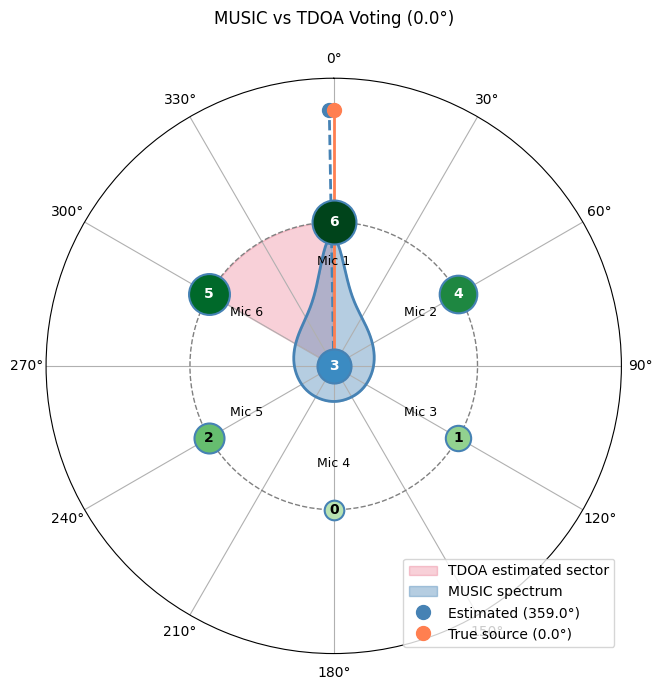

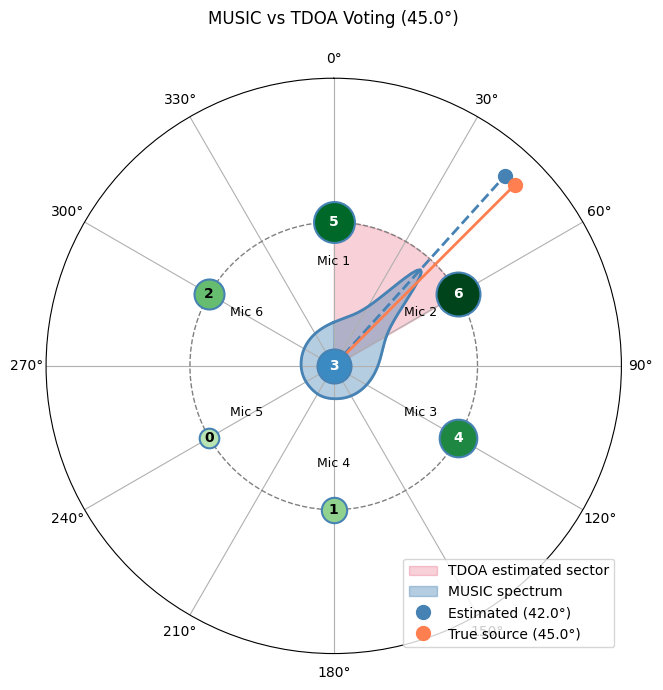

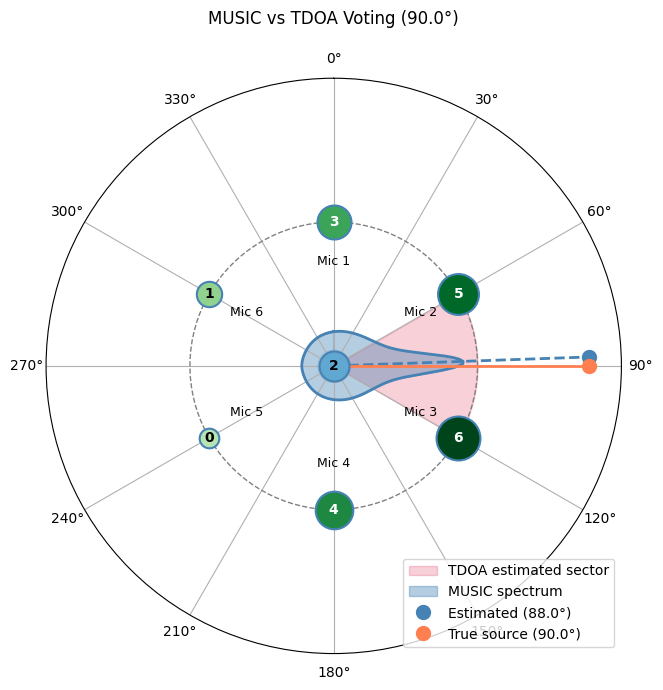

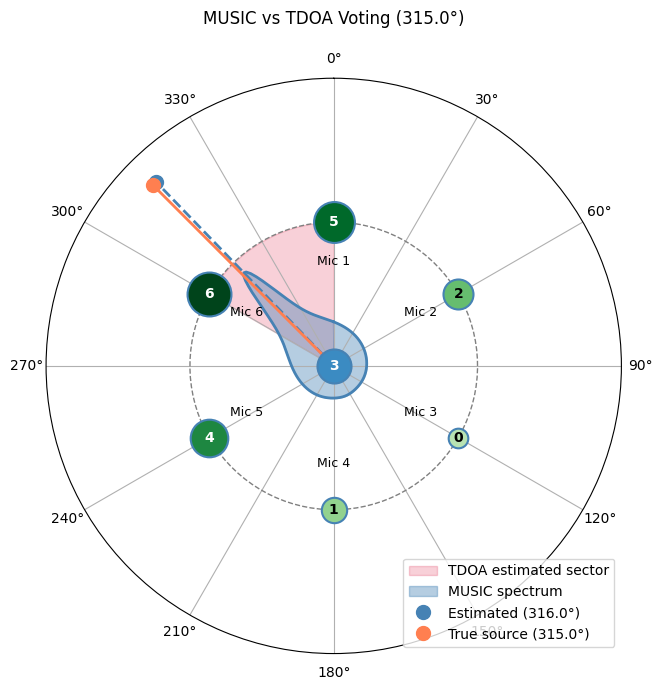

In [7]:
def plot_comparison(doa, scores, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    
    
##### Voting
    max_score = max(scores.values())

    # Outer mics 
    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        size = 200 + 800 * intensity
        color = cm.Greens(0.3 + 0.7 * intensity)

        ax.scatter(a, mic_r, s=size, color=color, zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 0.7), ha='center', fontsize=9)

    # Centre mic
    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    size_c = 200 + 800 * intensity_c
    color_c = cm.Blues(0.3 + 0.7 * intensity_c)

    ax.scatter(0, 0, s=size_c, color=color_c, zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)
    
    # Winning sector
    outer_scores = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer_scores.items(), key=lambda x: -x[1])
    winning_mic = int(sorted_mics[0][0])
    second_mic = int(sorted_mics[1][0])

    a1 = mic_angles_deg[winning_mic - 1]
    a2 = mic_angles_deg[second_mic - 1]

    delta = ((a2 - a1 + 180) % 360) - 180

    if delta >= 0:
        sector_start = np.radians(a1)
        sector_end = np.radians(a1 + delta)
    else:
        sector_start = np.radians(a1 + delta)
        sector_end = np.radians(a1)

    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='crimson',
                label='TDOA estimated sector')
    

##### MUSIC
    # MUSIC spectrum 
    azimuth = doa.grid.azimuth
    spectrum = doa.grid.values
    spectrum_norm = spectrum / spectrum.max()

    spectrum_r_min = 0.005
    spectrum_r_max = mic_r * 0.9
    spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

    ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4,
                    color='steelblue', label='MUSIC spectrum')
    ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

    # Estimated DOA
    estimated_rad = doa.azimuth_recon[0]
    estimated_deg = np.degrees(estimated_rad)
    ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue',
            linestyle='--', linewidth=2)
    ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10,
            label=f'Estimated ({estimated_deg:.1f}°)')

    # Array 
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # True source
    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'MUSIC vs TDOA Voting ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower right')
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)
    
    
for angle_key in recordings.keys():
    doa = music_results[angle_key][1]
    scores = vote_results[angle_key]
    plot_comparison(doa, scores, float(angle_key), f"music_{angle_key}")